# Assignment 6: Categorical Data and Chi-Square Analysis
Authored by Kristian M. P. Dashnaw (344849) & Katrine B. Aamand (344848) <br>
Based on assignment 6 description (https://rbrooksdk.github.io/STA1_26/assignments/assignment_06_categorical_data/)

## Table of Contents

1. **Part 1 — Safety-event overview**
    - 1.1 Observational Unit, Population, Variables, and Sampling Design
    - 1.2 Frequency Counts and Site-by-Type Contingency Table
    - 1.3 Bar Charts and Why Not a Histogram
    - 1.4 Largest Visible Differences
2. **Part 2 — Goodness of fit to the historical event mix**
    - 2.1 Hypotheses, Expected Counts, and Expected-Count Guideline
    - 2.2 Contributions, $\chi^2$, Degrees of Freedom, and SciPy Verification
    - 2.3 Largest Contributing Categories
    - 2.4 Contextual Conclusion and Why the Cause Is Not Identified
3. **Part 3 — Are event profiles homogeneous across sites?**
    - 3.1 Homogeneity vs. Independence and Hypotheses
    - 3.2 Expected Counts, Minimum, and Degrees of Freedom
    - 3.3 Pearson Chi-Square Test
    - 3.4 Pearson and Adjusted Residuals with Heatmap
    - 3.5 Cramér's $V$
    - 3.6 Monte Carlo Permutation Check
4. **Part 4 — A sparse $2\times2$ safety table**
    - 4.1 Observed $2\times2$ Table, Row Percentages, and Hypotheses
    - 4.2 Expected Counts and Why the Chi-Square Approximation Is Questionable
    - 4.3 Fisher's Exact Test
    - 4.4 Why Not Pool, and Recommended Further Evidence
5. **Part 5 — AI-Use and Conclusion**
    - AI-Use Statement
    - Overall Conclusion

## Working Notes (DELETE BEFORE HANDIN)

**Overview (from the assignment description):**

> In this mini-project, you will analyse counts and categorical outcomes. You will compare an observed event mix with a historical model, compare event distributions across sites, locate the cells driving a contingency-table result, and choose an exact alternative for a sparse $2\times2$ table.

**Practical information (from the assignment description):**

> - **Group size:** 2–4 students
> - **Submission:** one executed Jupyter notebook in English
> - **Expected workload:** approximately 5–8 hours in total
> - **Statistical scope:** Session 11 and Brooks, Chapter 11
> - **Required method:** Python throughout

**Preparation and data (from the assignment description):**

> Review [Session 11 — Categorical Data and Chi-Square Tests](https://rbrooksdk.github.io/STA1_26/11_Categorical_Data_and_Chi_Square_Tests/), [Tutorial 11](https://rbrooksdk.github.io/STA1_26/11_Categorical_Data_and_Chi_Square_Tests/Tutorial_11_notebook/), and [Brooks: Chapter 11](https://docs.google.com/viewer?url=https://raw.githubusercontent.com/RBrooksDK/STA_book_v1/main/main.pdf).
>
> Use [assignment06_safety_events.csv](./data/assignment06_safety_events.csv). Begin with the title, group members, table of contents, imports, and the file loaded from a local data folder.

**How to present the work (from the assignment description):**

> Chi-square methods use counts. Show observed and expected counts before reporting a test. State the study design and statistical question, inspect expected counts, and supplement a global result with conditional proportions, residuals, and an effect magnitude.

**Working with AI (from the assignment description):**

> AI may help construct tables, calculate expected counts and residuals, implement simulations, identify an exact alternative, and critique interpretations. You remain responsible for checking that the question, design, and method match. Part 5 documents your use.

**Theory and code at the oral exam (from the assignment description):**

> The concepts below are the theory connected to this assignment. The oral examination will sample from this material; it is not expected to cover every item.
>
> Be prepared to use examples from this assignment to explain categorical counts, goodness-of-fit tests, contingency tables, independence versus homogeneity, expected counts, Pearson's $\chi^2$, degrees of freedom, approximation conditions, category contributions, Pearson and adjusted residuals, Cramér's $V$, permutation or Monte Carlo checks, sparse tables, pooling, Fisher's exact test, and responsible conclusions from categorical studies.
>
> You need not memorise code, but you must understand each table, expected count, test, diagnostic, and conclusion. AI use does not change this requirement.

In [1]:
#Imports:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load the data file:
print("\nSafety_Events.csv, first 5 rows:")
safetyEventsData_unmodified = pd.read_csv('data/assignment06_safety_events.csv', delimiter = ',')
display(safetyEventsData_unmodified.head(5))

print(f"Number of entries:\n{safetyEventsData_unmodified.count()}\n")

print(f"site types: {safetyEventsData_unmodified['site'].unique()}\n")
print(f"event types: {safetyEventsData_unmodified['event_type'].unique()}\n")

siteCounts = safetyEventsData_unmodified['site'].value_counts()
eventCounts = safetyEventsData_unmodified['event_type'].value_counts()
siteIds = safetyEventsData_unmodified.groupby('site')['event_id'].agg(['first', 'last'])

print(f"number of north site entries    : {siteCounts['north']} (event_id {siteIds.loc['north', 'first']} to {siteIds.loc['north', 'last']})")
print(f"number of central site entries  : {siteCounts['central']} (event_id {siteIds.loc['central', 'first']} to {siteIds.loc['central', 'last']})")
print(f"number of coastal site entries  : {siteCounts['coastal']} (event_id {siteIds.loc['coastal', 'first']} to {siteIds.loc['coastal', 'last']})\n")

print(f"number of mechanical event types: {eventCounts['mechanical']}")
print(f"number of network event types   : {eventCounts['network']}")
print(f"number of sensor event types    : {eventCounts['sensor']}")
print(f"number of power event types     : {eventCounts['power']}\n")

print(f"is each event_id unique?        : {safetyEventsData_unmodified['event_id'].is_unique}")


Safety_Events.csv, first 5 rows:


,event_id,site,event_type
0,1,north,mechanical
1,2,north,network
2,3,north,sensor
3,4,north,network
4,5,north,sensor


Number of entries:
event_id      270
site          270
event_type    270
dtype: int64

site types: <StringArray>
['north', 'central', 'coastal']
Length: 3, dtype: str

event types: <StringArray>
['mechanical', 'network', 'sensor', 'power']
Length: 4, dtype: str

number of north site entries    : 90 (event_id 1 to 90)
number of central site entries  : 90 (event_id 91 to 180)
number of coastal site entries  : 90 (event_id 181 to 270)

number of mechanical event types: 64
number of network event types   : 70
number of sensor event types    : 109
number of power event types     : 27

is each event_id unique?        : True


<br><br><br>

---

<br>

## Part 1: Safety-event overview

The file [assignment06_safety_events.csv](./data/assignment06_safety_events.csv) contains recorded safety events from three sites. Each event has a `site` and an `event_type`: sensor, network, mechanical, or power.

For part 1 - we'll be using the Nine-step categorical analysis workflow described in the course book ch. 11.6, p. 165:

A defensible categorical analysis proceeds in this order:

1. state the target population, observational unit, categorical variables, and how units were sampled or assigned;
2. decide whether the question is goodness of fit, independence, or homogeneity;
3. present observed counts together with relevant sample or conditional proportions;
4. state $H_0$ and $H_1$ in both probability notation and contextual language;
5. calculate expected counts, identify any fitted parameters, and state the correct degrees of freedom;
6. check independence, category definitions, expected counts, and whether chi-square, simulation, or an exact alternative is justified;
7. report the test statistic, degrees of freedom, and $p$-value without describing the $p$-value as the probability that $H_0$ is true;
8. examine conditional proportions, cell contributions or residuals, and an effect magnitude such as Cramér's $V$; and
9. conclude in the language of the categories, including practical importance, design limitations, and the distinction between association and causation.

<br><br>
### 1.1 Identify the observational unit, population of interest, variables, categories, and whether the data represent one jointly classified sample or separate site samples. State what additional sampling information is needed for broad generalisation.

Authored by Kristian

#### Step 1: State the target population, observational unit, categorical variables, and how units were sampled or assigned:

|                                    |                                                                                                     |
|:----------------------------------:|:---------------------------------------------------------------------------------------------------:|
|         Observational Unit         |        Each recorded safety event from one of three sites, labelled by site and event_type.         |
|       Population of Interest       |         All safety events that occur on the three sites that the events were collected from         |
|    Categorical variable 1: site    |            Nominal** categories of type north (n=90), central (n=90) and coastal (n=90)             |
| Categorical variable 2: event_type | Nominal** categories of type sensor (n=109), network (n=70),<br/>mechanical (n=64) and power (n=27) |

*(Nominal = Has no natural order!)*

Each event falls into exactly one category of each variable. There are 270 event_ids in total, one for each observational unit and each observational unit has both a site and an event_type value. There are in total 270 entries in the site column and 270 entries in the event_type column, matching the 270 total event_ids.

The data represents **separate site samples**, which can be observed in the data where event_ids 1 - 90 are associated with the north site, event_ids 91 - 180 with the central site and event_ids 181 - 270 with the coastal site. This indicates that events were recorded separately for each site and combined into a single dataset later. This exact count of 90 safety events at each site also indicates that the site totals were **fixed by the data collection**, rather than coming from one sample of events classified by site afterwards, whose site totals would vary at random had this been the case. **The events were observed, not assigned**, since each event’s site is simply where it happened, and no one chose or randomly assigned it. The data can therefore show associations between site and event type, but not their causes. We cannot verify from the data that the events are independent, since one fault may trigger several recorded events (e.g. a power failure followed by network and sensor events), and repeated events from the same equipment or period may be related.

**Additional information needed for broad generalization**:
We do not know how the data was sampled, such as over which period of time, how often, whether sampling happened in parallel or one site at a time. We also don't know whether each site reports these events the same way - was it a foreman (human) at each site who reported safety events manually? is it some mechanical system? Is it a sensor? Is it a touring inspection team? We simply don't know, based only on the provided data. How about training level of personnel at each site, is that similar? Are the sites working conditions and work types comparable? Are sites staffed at similar levels, or are some sites understaffed? Are equipment and tools of similar types, similar quality and at similar maintenance levels between each site? Are all three sites operated by the same company, under the same management?

All of the above, and more information, would be required in order to make any broad generalization claims from this data.

<br><br>
### 1.2 Create overall frequency counts and percentages for event type. Create a site-by-type contingency table with row totals, column totals, and row percentages.

Authored by Kristian

Although this was already reported earlier, we'll re-report this here, using python:

In [2]:
# Kristian
eventOrder = ['sensor', 'network', 'mechanical', 'power']
siteOrder = ['north', 'central', 'coastal']

# Overall frequency counts and percentages for event type
eventTable = pd.DataFrame({'count': eventCounts[eventOrder]})
eventTable['percent'] = (eventTable['count'] / eventTable['count'].sum() * 100).round(1)
eventTable.loc['Total'] = [eventTable['count'].sum(), 100.0]
eventTable = eventTable.astype({'count': int})
print("Overall event-type counts and percentages:")
display(eventTable)

# Site-by-type contingency table with row and column totals
contingencyTable = pd.crosstab(safetyEventsData_unmodified['site'], safetyEventsData_unmodified['event_type'],
                               margins=True, margins_name='Total').loc[siteOrder + ['Total'], eventOrder + ['Total']]
print("\nSite-by-type contingency table (counts):")
display(contingencyTable)

# Row percentages: each cell divided by its row (site) total
rowPercentages = (contingencyTable.div(contingencyTable['Total'], axis=0) * 100).round(1)
print("\nRow percentages (event-type distribution within each site, %):")
display(rowPercentages)

Overall event-type counts and percentages:


,count,percent
event_type,,
sensor,109,40.4
network,70,25.9
mechanical,64,23.7
power,27,10.0
Total,270,100.0



Site-by-type contingency table (counts):


event_type,sensor,network,mechanical,power,Total
site,,,,,
north,48,20,15,7,90
central,29,29,21,11,90
coastal,32,21,28,9,90
Total,109,70,64,27,270



Row percentages (event-type distribution within each site, %):


event_type,sensor,network,mechanical,power,Total
site,,,,,
north,53.3,22.2,16.7,7.8,100.0
central,32.2,32.2,23.3,12.2,100.0
coastal,35.6,23.3,31.1,10.0,100.0
Total,40.4,25.9,23.7,10.0,100.0


Based on these reported frequencies, we can build the site-by-type contingency table:

|         | sensor count | sensor percent | network count | network percent | mechanical count | mechanical percent | power count | power percent | total count | total percent |
|:-------:|:------------:|:--------------:|:-------------:|:---------------:|:----------------:|:------------------:|:-----------:|:-------------:|:-----------:|:-------------:|
|  north  |      48      |     53.3%      |      20       |      22.2%      |        15        |       16.7%        |      7      |     7.8%      |     90      |    100.0%     |
| central |      29      |     32.2%      |      29       |      32.2%      |        21        |       23.3%        |     11      |     12.2%     |     90      |    100.0%     |
| coastal |      32      |     35.6%      |      21       |      23.3%      |        28        |       31.1%        |      9      |     10.0%     |     90      |    100.0%     |
|  total  |     109      |     40.4%      |      70       |      25.9%      |        64        |       23.7%        |     27      |     10.0%     |     270     |               |

<br><br>
### 1.3 Create suitable bar charts for the overall distribution and the conditional event-type distributions by site. Explain why a histogram is not appropriate for unordered categories.

Authored by Kristian

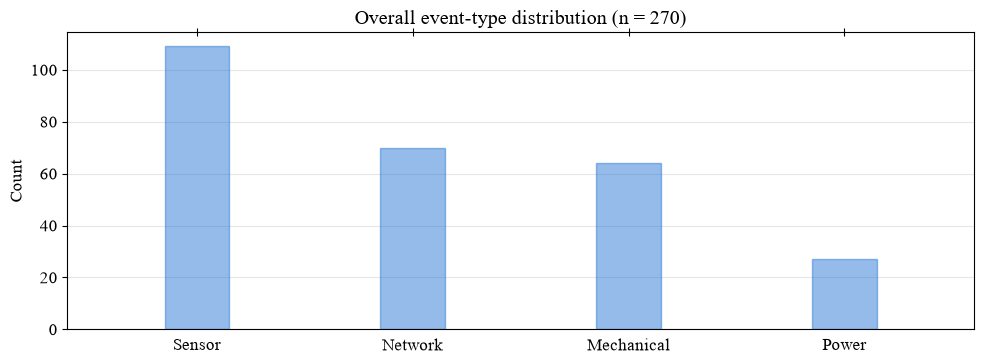

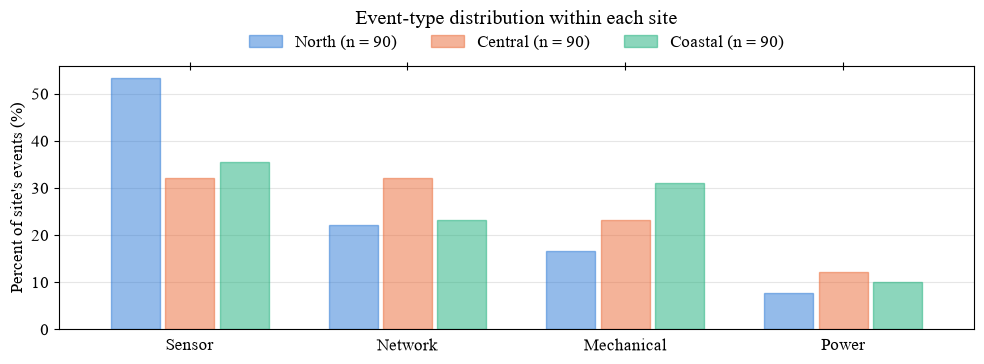

In [3]:
# Kristian

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'STIXGeneral', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'font.size': 12,
    'axes.grid': True,
    'axes.grid.axis': 'y',
    'grid.color': '#e6e6e6',
    'grid.linewidth': 0.8,
    'axes.axisbelow': True,
})

siteColours = {'north': '#2a78d6', 'central': '#eb6834', 'coastal': '#1baf7a'}
x = np.arange(len(eventOrder))


def bookAxes(ax):
    ax.set_xticks(x, [e.capitalize() for e in eventOrder])
    ax.tick_params(axis='x', bottom=False, top=True, direction='inout', length=6)
    ax.set_xlim(-0.6, len(eventOrder) - 0.4)


# Chart 1: overall event-type distribution (counts)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(x, eventTable.loc[eventOrder, 'count'], width=0.3,
       color='#2a78d6', alpha=0.5, edgecolor='#2a78d6', linewidth=1)
bookAxes(ax)
ax.set_ylabel('Count')
ax.set_title(f"Overall event-type distribution (n = {eventTable.loc['Total', 'count']})")
plt.tight_layout()
plt.show()

print("\n")

# Chart 2: conditional event-type distribution within each site (row percentages)
width = 0.25
fig, ax = plt.subplots(figsize=(10, 3.8))
for k, site in enumerate(siteOrder):
    ax.bar(x + (k - 1) * width, rowPercentages.loc[site, eventOrder], width=width * 0.9,
           color=siteColours[site], alpha=0.5, edgecolor=siteColours[site], linewidth=1,
           label=f"{site.capitalize()} (n = {contingencyTable.loc[site, 'Total']})")
bookAxes(ax)
ax.set_ylabel("Percent of site's events (%)")
ax.set_title('Event-type distribution within each site', pad=30)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

#### Why a histogram is not appropriate for unordered categories
A histogram is not appropriate for the data in this study, due to the categorical nature of the data and the lack of a natural order among the categories. From the course book ch. 1.2. p. 8, we have that "A key feature of a histogram is that the bars are placed directly adjacent to one another, reflecting the continuous nature of the bins."

Since we in this study are dealing with 4 different nominal categories, across 3 different sites, we cannot represent this properly on a histogram, since the categories have no numerical scale and therefore no continuous bins. No event type lies before, after or between another, so the order of the bars is our own choice, and rearranging them would change the apparent shape of a histogram. Instead, we use bar charts with separated bars, which show each category’s count or percentage without implying such a scale.

<br><br>
### 1.4 Describe the largest visible differences without yet treating them as statistically established or causal.

Authored by Kristian

**Between event-types:**
The largest visible differences lie between the sensor and the power event types, which is reflected across all 3 sites. Sensor derived safety events occur at approximately 4 times (30-53%) the frequency of power derived safety events (approx 8-12%).

**Between sites:**
The northern site appears to have substantially more sensor derived safety events (approx 53%) compared to the other 2 sites who both sit around approx 34%. The Coastal site appears to have a higher frequency of mechanical derived safety events (approx 32%) compared to the other sites, who sit between approximately 17% and 24%. The central site has a higher share of network derived safety events, sitting at approx 32% compared to the approx 23% of the other 2 sites.

<br><br><br>

---

<br>

## Part 2: Goodness of fit to the historical event mix

The historical reference model, specified before the new data were examined, is

$$
P(\text{sensor})=0.50,\quad
P(\text{network})=0.25,\quad
P(\text{mechanical})=0.15,\quad
P(\text{power})=0.10.
$$

<br><br>
### 2.1 State the goodness-of-fit hypotheses. Calculate expected counts as $np_j$, show an observed-versus-expected table, and check the expected-count guideline.

In [4]:
# TODO: Katrine

<br><br>
### 2.2 Calculate each category's contribution $(O-E)^2/E$, their sum $\chi^2$, and the degrees of freedom. Verify with `scipy.stats.chisquare` and report the $p$-value and decision at $\alpha=0.05$.

In [5]:
# TODO: Katrine

<br><br>
### 2.3 Identify which categories contribute most and describe whether each is above or below its expected count. Explain why the global test alone does not provide this information.

In [6]:
# TODO: Katrine

<br><br>
### 2.4 State a contextual conclusion and explain why a difference from the historical mix does not identify its operational cause.

In [7]:
# TODO: Katrine

<br><br><br>

---

<br>

## Part 3: Are event profiles homogeneous across sites?

Treat the site records as separate samples and ask whether the event-type distribution is the same at all three sites.

<br><br>
### 3.1 Explain why this is naturally a test of homogeneity. State $H_0$ and $H_1$, and explain how an independence study would differ in design even though the Pearson calculation can be identical.

Authored by Kristian.

Comparing to the Nine-step categorical analysis workflow described in the course book ch. 11.6, p. 165, this question deals with steps 2 and 4.

#### Step 2: Decide whether the question is goodness of fit, independence, or homogeneity;
To assist in explaining why treating the records associated with each of the 3 sites as separate samples is naturally a test of homogeneity, we'll begin by plotting a bar chart showing how the counts of each event type are distributed between the 3 sites.

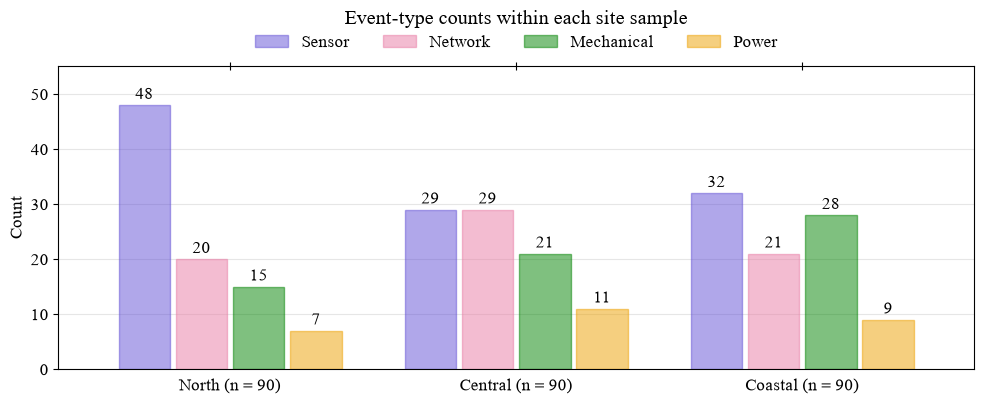

In [8]:
# Kristian
# Event-type counts within each site, with the sites as three separate samples
eventColours = {'sensor': '#6250d6', 'network': '#e87ba4', 'mechanical': '#008300', 'power': '#eda100'}
siteSamples = contingencyTable.loc[siteOrder, eventOrder]  # counts only, without the totals

x = np.arange(len(siteOrder))  # one group of bars per site
width = 0.2                    # width of each event-type bar

fig, ax = plt.subplots(figsize=(10, 4.2))
for k, event in enumerate(eventOrder):
    offset = (k - 1.5) * width  # places the four bars side by side around the site's centre
    bars = ax.bar(x + offset, siteSamples[event], width=width * 0.9,
                  color=eventColours[event], alpha=0.5, edgecolor=eventColours[event], linewidth=1,
                  label=event.capitalize())
    ax.bar_label(bars, padding=2)  # writes each bar's count above it

ax.set_xticks(x, [f"{site.capitalize()} (n = {contingencyTable.loc[site, 'Total']})" for site in siteOrder])
ax.tick_params(axis='x', bottom=False, top=True, direction='inout', length=6)
ax.set_xlim(-0.6, len(siteOrder) - 0.4)
ax.set_ylim(0, siteSamples.values.max() * 1.15)  # room for the count labels
ax.set_ylabel('Count')
ax.set_title('Event-type counts within each site sample', pad=30)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=4, frameon=False)
plt.tight_layout()
plt.show()

##### Why is this naturally a test of homogeneity?
As found in 1.1, the data consist of three separate site samples of 90 events each, with the site totals fixed by the data collection. Comparing the event-type distributions of separate samples is naturally a test of homogeneity. Had the event-type distribution been the same at all three sites, we should expect the distributions of the various event types to be similar between the site samples, apart from chance variation.

Reviewing the plotted bar chart, the Central and Coastal sites appear more similar to each other than either is to the North site, mainly through North's larger sensor count (48 against 29 and 32). This is only a preliminary impression before doing any calculations.

<br>

##### Step 4: State $H_0$ and $H_1$ in both probability notation and contextual language;
Derived from the explanation above, our hypothesis for a homogeneity test then becomes:

Let $p_{s,j}$ be the probability that a safety event at site $s$ is of event type $j$.

$H_0$: $p_{\text{north},j} = p_{\text{central},j} = p_{\text{coastal},j}$ for every event type $j$, i.e. all three sites have the same four event-type probabilities.

$H_1$: at least one event-type probability differs between at least two sites, i.e. the sites do not all share the same event-type distribution.

<br>

##### How would an independence study differ in design even though the Pearson calculation can be identical?
For this to be an independence study, the data would have to come from a single random sample of safety events drawn from all three sites combined, with both site and event type recorded for each event. The site totals would then vary at random instead of being fixed at 90, and the question would be whether site and event type are associated, $H_0$: $p_{ij} = p_{i+} \cdot p_{+j}$ for every cell. Here $p_{ij}$ would be the probability that an event is from site $i$ and of event type $j$, $p_{i+}$ the probability that an event is from site $i$ (the row probability), and $p_{+j}$ the probability that an event is of type $j$ (the column probability). The Pearson calculation can still be identical, since both designs estimate the expected counts from the margins, $E_{ij} = (\text{row } i \text{ total})(\text{column } j \text{ total})/n$, and use the same $\chi^2$ statistic; only the sampling design and the wording of the conclusion differ.

<br><br>
### 3.2 Calculate every expected count using the row and column margins, check their minimum, and calculate the degrees of freedom $(r-1)(c-1)$.

In [9]:
# TODO: Kristian

<br><br>
### 3.3 Perform the Pearson chi-square test. Report $\chi^2$, degrees of freedom, $p$, decision, and a conclusion in terms of site event profiles.

In [10]:
# TODO: Kristian

<br><br>
### 3.4 Calculate Pearson and adjusted residuals and display the adjusted residuals as a labelled heatmap. Use their signs and magnitudes together with row percentages to identify the cells driving the global pattern.

In [11]:
# TODO: Kristian

<br><br>
### 3.5 Calculate Cramér's $V$ and interpret it as a descriptive association magnitude without applying a universal engineering cutoff or treating it as causation.

In [12]:
# TODO: Kristian

<br><br>
### 3.6 With seed 2026 and at least 5,000 permutations, shuffle site labels while holding event types fixed. Compare the Monte Carlo tail probability with the chi-square reference result and explain what the simulation checks.

In [13]:
# TODO: Kristian

<br><br><br>

---

<br>

## Part 4: A sparse $2\times2$ safety table

A small pilot study compares an existing and a modified interlock. An unwanted trip occurred in 1 of 20 existing-system trials and 7 of 20 modified-system trials.

<br><br>
### 4.1 Construct the $2\times2$ table of observed counts and calculate row percentages. State the comparison and hypotheses.

In [14]:
# TODO: Katrine

<br><br>
### 4.2 Calculate the expected counts under independence or homogeneity. Explain why the usual chi-square approximation is questionable here.

In [15]:
# TODO: Katrine

<br><br>
### 4.3 Use Fisher's exact test as the primary analysis. Report the odds ratio returned by SciPy, the two-sided $p$-value, decision, and contextual conclusion.

In [16]:
# TODO: Katrine

<br><br>
### 4.4 Explain why categories or outcomes must not be pooled merely to make a test significant or satisfy a rule. State what additional evidence or larger study you would recommend.

In [17]:
# TODO: Katrine

<br><br><br>

---

<br>

## Part 5: AI-Use and Conclusion
### AI-use
> State which AI tools you used, what they contributed, what you changed or rejected, and how you verified the work. A short paragraph or table is sufficient.

#### In part 1 - Claude Opus 5.5
`Assigned to: Kristian`
- AI was used to provide feedback on the manually drafted versions of task solutions.
- Assisted in resolving markdown syntax (latex) and python syntax for various formulas and operations.

##### What changed/got rejected:
- AI Generated the python code for the counts and frequencies in 1.2.
- AI Generated the python code for the bar charts in 1.3.

##### How we checked that the final work was correct:
- Added the counts and frequencies together by hand and compared against the python computed counts and frequencies.
<br><br>

#### In part 2 - [AI tool and model]
`Assigned to: ___`
- *TODO: what the AI contributed*
##### What changed/got rejected:
- *TODO*
##### How we checked that the final work was correct:
- *TODO*
<br><br>

#### In part 3 - Claude Opus 5.5
`Assigned to: Kristian`
- AI was used to provide feedback on the manually drafted versions of task solutions.
- Assisted in resolving markdown syntax (latex) and python syntax for various formulas and operations.

##### What changed/got rejected:
- AI Generated the python code for the bar chart in 3.1.
- Helped make my explanations in 3.1 more precise.

##### How we checked that the final work was correct:
- Verified counts and shape of the bar chart in 3.1 against the values found in part 1.

<br><br>

#### In part 4 - [AI tool and model]
`Assigned to: ___`
- *TODO: what the AI contributed*
##### What changed/got rejected:
- *TODO*
##### How we checked that the final work was correct:
- *TODO*
<br><br>

_____________

### Overall conclusion
> Write approximately 150–250 words comparing the goodness-of-fit, homogeneity, and sparse-table questions. Include statistical evidence, the categories driving each result, effect magnitude where appropriate, assumptions, and practical limitations.
>
> Do not use chi-square on binned continuous data as a normality test. Normality assessment for quantitative data remains a different question addressed with methods such as QQ-plots.

*TODO*

## Submission Checklist

- [ ] Tests are calculated from counts, not percentages.
- [ ] Goodness of fit and two-way tables are distinguished.
- [ ] Observed and expected counts and degrees of freedom are shown.
- [ ] Expected-count adequacy is checked before using the approximation.
- [ ] Residuals and conditional proportions locate the important cells.
- [ ] Cramér's $V$ is not interpreted causally.
- [ ] Fisher's exact test is used for the sparse $2\times2$ case.
- [ ] Part 5 contains AI-use and conclusion.
- [ ] All code is executed and output is visible.